# Random Forest para regresión/clasificación

## Explicación y teoria

### Objetivo y motivación
* **¿Que es random forest?**  

Es un metodo de **aprendizaje supervisado** realizado por Leo Breiman y Adele Cutler, este puede resolver problemas de regresión o clasificación y se basa en un conjunto de multiples arboles de decisión, pero, en lugar de que estos trabajen de manera independiente, colaboran entre si para que las predicciónes que se realizen sean más precisas. 

*Arboles de decisión:* estos analizan distintas variables y dividen los datos en ramas que clasifican o predicen resultados, sin embargo si se trabaja con un solo arbol se ajusta demasiado a los datos de entrenamiento por lo que hay un bajo sesgo pero una alta varianza y un sobreajuste del modelo.

Al trabajar con random forest los problemas de generalización se solucionan puesto que se utilizan varios arboles con datos y caracteristicas seleccionadas al azar, independientes y poco correlacionados, se reduce la varianza del modelo sin incrementar el sesgo,aumentando así su estabilidad.

* **¿Para que sirve y cuando se utiliza?**

    Es una de las herramientas mas populares en ciencia de datos por su versatilidad siendo que resuelve dos tipos de porblemas principalmente:

    - Clasificación: predice una categoria o variable discreta, un ejemplo puede ser detefctar si un correo es spam.

    - Regresión: predice un valor numerico continuo, un ejemplo es estimar el volumen de ventas de una tienda.

Adicionalmente, esta herramienta se suele aplicar en varias industrias para tomar desiciones empresariales, sirve para atención medica, comercio electronico o incluso en finanzas donde por ejemplo se usa para evaluar los clientes con alto riesgo crediticio.

### Teoria: 

* **¿como funciona internamente el algoritmo?**

    * *bootstrap sampling (bagging):*
    
    Es la primera fase que sigue el algoritmo, este selecciona aleatoriamente muestras del conjunto original de datos, de esta manera cada observación aparece en mas de una muestra lo que permite que cada arbol entrene con datos variados para añadir diversidad en el modelo. la probabilidad de que una observación quede seleccionada es de aproximada del 63.2%, dejando un 36.8% fuera (muestras OOB)

    
    * *Selección aleatoria de caracteristicas:*
    
    En esta fase, cada arbol elije de manera aleatoria un subconjunto de variables en cada división, esto reduce la correlación entre arboles y evita que uno o varios predictores dominen la decisión final.
    
    * *Ensamble de arboles de decisión:*
    
    Cada muestra bootstrap, genera un arbol independiente que se entrena sin podar (reducir el tamaño o profundidad del arbol, eliminando ramas que aportan poco valor o añaden complejidad innecesaria), lo que permite que el modelo capture patrones, interacciones y relaciónes en los datos, Una vez construidos todos los arboles forman un random forest. 
    
    * *Votación/agregación de resultados:* Dependiendo el tipo de problema (regresión o clasificación), la determinación de la predicción varia:
    
        - Clasificación: Cada arbol "vota" por una clase y la clase ganadora por mayoria es la predicción final del bosque.

        - Regresión: el resultado se obtiene cuando se calcula el promedio de las predicciones de todos los arboles.
        
    * *Validación del modelo:*
    
        * Validación Out-Of-Bag: El algoritmo valida su propio rendimiento pues debido a que cada arbol usa una muestra bootstrap, queda al rededor del 36,8% de datos fuera de cada entrenamiento, estas observaciones conocidas como muestras OOB se usan automaticamente como validación del rendimiento del modelo (presición y error) sin necesidad de separar manualmente un conjunto de validación adicional.

        * División tradicional de datos: Es la versión manual de la validación OOB. Se usa el conjunto con el que se ajustan los arboles de ranom forest para ajustar hiperparametros (parametros esenciales para entrenar el algoritmo), este se reserva hasta el final para medir la capacidad de generalización de datos nunca vistos. 

        * Validación cruzada: en conjunto de entrenamineto se divide en k bloques, el modelo entonces se entrena K veces usando K-1 bloques para ajustar y 1 bloque para validar. Es la tecnica recomendada para ajustar hiperparametros.

        * Metricas de evaluación de regresión: se calculan metricas como el Root Mean Squared Error (penaliza los errores graves), Mean Absolute Error (mide el error promedio absoluto en la misma unidad de la variable) y el coeficiente de determinación (R2- indica la proporción de la varianza respecto a la variable que el bosuqe quiere explicar).

        * Analisis de residuos: Grafica los errores de predicción frente a los valores predichos, de esta manera se identifica si existen sesgos sistematicos o heterocedasticidad (la varianza del error aumenta mientras la variable que se quiere explicar aumenta)

* **Importancia de variables (Feature importance)**

    Los modelos Random Forest ofrecen varias formas de entender como influyen las variables en las predicciones, para esto las dos formas principales son:

    * *Importancia basada en impureza (MDI):*
    
   Para este metodo se utilizan los datos de entrenamiento, este busca medir la reducción acumulada de varianza en los cortes de nodo, basicamente responde a la pregunta ¿cuanto contribuye la variable a dividir los nodos de forma limpia durante la construcción del random forest?.

   Tiene como ventaja que se calcula automaticamente mientras los arboles se entrenan, sin embargo, tienden a sobreestimar la importancia de variables continuas, categoricas unicas (porque generan mas puntos de corte potenciales en el entrenamiento) y variables con ruido si el arbol es profundo.

    * *Importancia basada en permutación (MDA):*
    
   Para este metodo se utilizan los datos de validación (muestras OOB), este busca medir la pérdida de precisión al desordenar al azar una variable, basicamente responde a la pregunta ¿Cuánto empeora la capacidad predictiva real del modelo en datos no vistos (OOB) si destruimos la información de esta variable?

   Tiene como ventaja que mide el rendimiento real sobre datos no vistos y no esta sesgado por cardinalidad o tipo de variable, sin embargo, tiene un mayor costo computacional (requiere evaluar todo el conjunto de datos por variable predictora) y adicionalmente si dos variables estan fuertemente correlacionadas su importancia parecera menor de lo que realmente es.

* **Limitaciones del algoritmo**

    * *Limitaciones de extrapolación:*

    Random forest no puede extrapolar mas allá del rango de los datos de entrenamiento; Cada arbol hace predicciones basadas en las divisiones observadas en el entrenamiento, por esto mismo, la salida final queda acotada por los valores minimos y maximos del objetivo en el conjunto de datos (si el modelo vio objetivos entre 10 y 100 no podra predecir 150)

    * *Casos extremos:* 

    El modelo se ve afectado por datos de dimensión y dispersión muy alta como representaciones de texto, siendo que los arboles se vuelven ineficientes y no capturan patrones significativos.


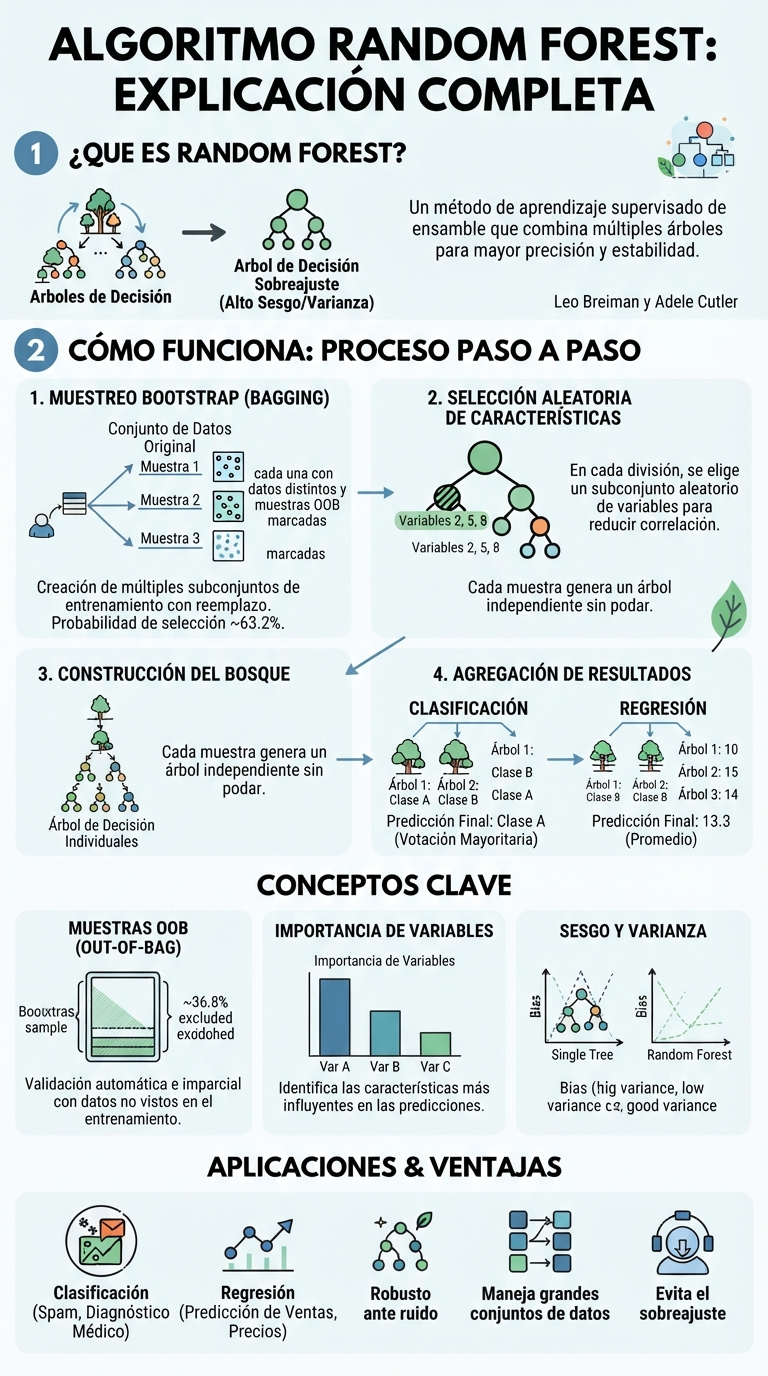

In [1]:
from IPython.display import Image, display

display(Image(filename='Infografia.jpg', width=1000))

## Ejemplo aplicado

### Limpieza de La base de datos

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
import chardet
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
with open('spotify-2023.csv', 'rb') as f:
    result = chardet.detect(f.read())
    print(result)

{'encoding': 'iso8859-16', 'confidence': 0.01558481133614436, 'language': 'pl', 'mime_type': 'text/plain'}


In [4]:
songs_df = pd.read_csv('spotify-2023.csv', encoding=result['encoding'], sep=',')

In [5]:
songs_df.dtypes

track_name              object
artist(s)_name          object
artist_count             int64
released_year            int64
released_month           int64
released_day             int64
in_spotify_playlists     int64
in_spotify_charts        int64
streams                 object
in_apple_playlists       int64
in_apple_charts          int64
in_deezer_playlists     object
in_deezer_charts         int64
in_shazam_charts        object
bpm                      int64
key                     object
mode                    object
danceability_%           int64
valence_%                int64
energy_%                 int64
acousticness_%           int64
instrumentalness_%       int64
liveness_%               int64
speechiness_%            int64
dtype: object

In [6]:
for col in songs_df.columns:
    songs_df[col] = pd.to_numeric(songs_df[col], errors='ignore')

songs_df['streams'] = songs_df['streams'].astype(str).str.replace(',', '', regex=False)
songs_df['streams'] = songs_df['streams'].str.strip()
songs_df['streams'] = pd.to_numeric(songs_df['streams'], errors='coerce')

# Revisar qué columnas quedaron numéricas
num_cols = songs_df.select_dtypes(include=['int64', 'float64']).columns
print("Columnas convertidas a numéricas:\n", num_cols)

Columnas convertidas a numéricas:
 Index(['artist_count', 'released_year', 'released_month', 'released_day',
       'in_spotify_playlists', 'in_spotify_charts', 'streams',
       'in_apple_playlists', 'in_apple_charts', 'in_deezer_charts', 'bpm',
       'danceability_%', 'valence_%', 'energy_%', 'acousticness_%',
       'instrumentalness_%', 'liveness_%', 'speechiness_%'],
      dtype='object')


C:\Users\anaso\AppData\Local\Temp\ipykernel_21696\2187691572.py:2: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  songs_df[col] = pd.to_numeric(songs_df[col], errors='ignore')


In [7]:
songs_df.dtypes

track_name               object
artist(s)_name           object
artist_count              int64
released_year             int64
released_month            int64
released_day              int64
in_spotify_playlists      int64
in_spotify_charts         int64
streams                 float64
in_apple_playlists        int64
in_apple_charts           int64
in_deezer_playlists      object
in_deezer_charts          int64
in_shazam_charts         object
bpm                       int64
key                      object
mode                     object
danceability_%            int64
valence_%                 int64
energy_%                  int64
acousticness_%            int64
instrumentalness_%        int64
liveness_%                int64
speechiness_%             int64
dtype: object

In [8]:
#LIMPIEZA DE LA COLUMNA 'STREAMS'

songs_df['streams'] = pd.to_numeric(songs_df['streams'], errors='coerce')
songs_df = songs_df.dropna(subset=['streams'])
songs_df['streams'] = songs_df['streams'].astype('int64')

print("Limpieza de streams completada.")
print("Tipo de dato actual de 'streams':", songs_df['streams'].dtype)

Limpieza de streams completada.
Tipo de dato actual de 'streams': int64


In [9]:
#LIMPIEZA DE NOMBRES DE COLUMNAS
songs_df.columns = songs_df.columns.str.replace('_%', '', regex=False)
songs_df.columns = songs_df.columns.str.replace('%', '', regex=False)
songs_df.rename(columns={'artist(s)_name': 'artist_name'}, inplace=True)

print("Nuevos nombres de columnas:\n", songs_df.columns.tolist())

Nuevos nombres de columnas:
 ['track_name', 'artist_name', 'artist_count', 'released_year', 'released_month', 'released_day', 'in_spotify_playlists', 'in_spotify_charts', 'streams', 'in_apple_playlists', 'in_apple_charts', 'in_deezer_playlists', 'in_deezer_charts', 'in_shazam_charts', 'bpm', 'key', 'mode', 'danceability', 'valence', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'speechiness']


In [10]:
songs_df.head()

,track_name,artist_name,artist_count,released_year,released_month,released_day,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,...,bpm,key,mode,danceability,valence,energy,acousticness,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2,2023,7,14,553,147,141381703,43,...,125,B,Major,80,89,83,31,0,8,4
1,LALA,Myke Towers,1,2023,3,23,1474,48,133716286,48,...,92,C#,Major,71,61,74,7,0,10,4
2,vampire,Olivia Rodrigo,1,2023,6,30,1397,113,140003974,94,...,138,F,Major,51,32,53,17,0,31,6
3,Cruel Summer,Taylor Swift,1,2019,8,23,7858,100,800840817,116,...,170,A,Major,55,58,72,11,0,11,15
4,WHERE SHE GOES,Bad Bunny,1,2023,5,18,3133,50,303236322,84,...,144,A,Minor,65,23,80,14,63,11,6


In [11]:
#Quitar comas y forzar conversión a numérico en Deezer y Shazam
for col in ['in_deezer_playlists', 'in_shazam_charts']:
    songs_df[col] = songs_df[col].astype(str).str.replace(',', '', regex=False)
    songs_df[col] = pd.to_numeric(songs_df[col], errors='coerce')
songs_df['in_shazam_charts'] = songs_df['in_shazam_charts'].fillna(0).astype('int64')

songs_df['key'] = songs_df['key'].fillna('Unknown')

print("Tipos actualizados para Deezer y Shazam:\n", songs_df[['in_deezer_playlists', 'in_shazam_charts']].dtypes)
print("\nNulos restantes en Shazam y Key:\n", songs_df[['in_shazam_charts', 'key']].isnull().sum())

Tipos actualizados para Deezer y Shazam:
 in_deezer_playlists    int64
in_shazam_charts       int64
dtype: object

Nulos restantes en Shazam y Key:
 in_shazam_charts    0
key                 0
dtype: int64


In [12]:
#Unir el año, mes y día en una fecha real (Datetime)
songs_df['release_date'] = pd.to_datetime(songs_df[['released_year', 'released_month', 'released_day']].rename(
    columns={'released_year': 'year', 'released_month': 'month', 'released_day': 'day'}
))

#Eliminar las columnas de fecha antiguas para no tener datos repetidos
songs_df.drop(columns=['released_year', 'released_month', 'released_day'], inplace=True)

#Aplicar One-Hot Encoding a 'key' y 'mode'
songs_df = pd.get_dummies(songs_df, columns=['key', 'mode'], drop_first=False)

#Asegurar que las nuevas columnas del One-Hot Encoding sean números (0 y 1) y no booleanos (True/False)
encoded_cols = [col for col in songs_df.columns if col.startswith('key_') or col.startswith('mode_')]
songs_df[encoded_cols] = songs_df[encoded_cols].astype(int)

print("Dimensiones finales para modelar:", songs_df.shape)

Dimensiones finales para modelar: (952, 34)


In [13]:
print("Dimensiones del dataset:", songs_df.shape)
print("\nTipos de columnas:\n", songs_df.dtypes)
print("\nValores nulos por columna:\n", songs_df.isnull().sum())

Dimensiones del dataset: (952, 34)

Tipos de columnas:
 track_name                      object
artist_name                     object
artist_count                     int64
in_spotify_playlists             int64
in_spotify_charts                int64
streams                          int64
in_apple_playlists               int64
in_apple_charts                  int64
in_deezer_playlists              int64
in_deezer_charts                 int64
in_shazam_charts                 int64
bpm                              int64
danceability                     int64
valence                          int64
energy                           int64
acousticness                     int64
instrumentalness                 int64
liveness                         int64
speechiness                      int64
release_date            datetime64[ns]
key_A                            int64
key_A#                           int64
key_B                            int64
key_C#                           int64
key_D   

In [14]:
num_cols = songs_df.select_dtypes(include=['int64', 'float64']).columns
print("\nEstadísticos descriptivos de variables numéricas:\n")
songs_df[num_cols].describe()


Estadísticos descriptivos de variables numéricas:



,artist_count,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,in_deezer_playlists,in_deezer_charts,in_shazam_charts,bpm,...,key_D,key_D#,key_E,key_F,key_F#,key_G,key_G#,key_Unknown,mode_Major,mode_Minor
count,952.000000,952.000000,952.000000,9.520000e+02,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,...,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,1.556723,5202.565126,12.022059,5.141374e+08,67.866597,51.963235,385.535714,2.669118,56.907563,122.553571,...,0.085084,0.034664,0.065126,0.093487,0.076681,0.100840,0.095588,0.099790,0.576681,0.423319
std,0.893331,7901.400683,19.582405,5.668569e+08,86.470591,50.628850,1131.078760,6.038152,157.513706,28.069601,...,0.279153,0.183023,0.246878,0.291267,0.266224,0.301275,0.294180,0.299877,0.494345,0.494345
min,1.000000,31.000000,0.000000,2.762000e+03,0.000000,0.000000,0.000000,0.000000,0.000000,65.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,874.500000,0.000000,1.416362e+08,13.000000,7.000000,13.000000,0.000000,0.000000,99.750000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,2216.500000,3.000000,2.905309e+08,34.000000,38.500000,44.000000,0.000000,2.000000,121.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,2.000000,5573.750000,16.000000,6.738690e+08,88.000000,87.000000,164.250000,2.000000,33.250000,140.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,8.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,12367.000000,58.000000,1451.000000,206.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Modelo y aplicación de la metodologia

#### Entrenamiento del modelo Random Forest

Como la variable objetivo `streams` representa una cantidad numérica continua, se utiliza un **RandomForestRegressor**.  
Se separan los datos en 80% para entrenamiento y 20% para prueba.


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Crear variables numéricas a partir de la fecha para conservar su información
songs_df['release_year'] = songs_df['release_date'].dt.year
songs_df['release_month'] = songs_df['release_date'].dt.month
songs_df['release_dayofyear'] = songs_df['release_date'].dt.dayofyear

# Rellenar posibles valores faltantes en Deezer con la mediana
songs_df['in_deezer_playlists'] = songs_df['in_deezer_playlists'].fillna(
    songs_df['in_deezer_playlists'].median()
)

# Variable objetivo
y = songs_df['streams']

# Variables predictoras:
# se excluyen identificadores de texto, la fecha original y la variable objetivo
X = songs_df.drop(columns=['streams', 'track_name', 'artist_name', 'release_date'])

# Asegurar que todas las variables usadas por el modelo sean numéricas
X = X.select_dtypes(include=['number'])

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Valores nulos en X:", X.isnull().sum().sum())


Dimensiones de X: (952, 33)
Dimensiones de y: (952,)
Valores nulos en X: 0


In [16]:
# División de los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)


Datos de entrenamiento: (761, 33)
Datos de prueba: (191, 33)


In [17]:
# Crear y entrenar el modelo Random Forest
modelo_rf = RandomForestRegressor(
    n_estimators=500,
    max_features='sqrt',
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente.")


Modelo Random Forest entrenado correctamente.


### Validación y conclusiones

#### Validación interna: Out-of-Bag (OOB score)

Cada árbol del bosque se entrena con una muestra bootstrap que no toma en consideración, en promedio, un 36.8% de las observaciones (muestras OOB). Random Forest puede usar automáticamente esas observaciones no vistas para estimar su propio desempeño, sin necesidad de un conjunto de prueba adicional. Esta métrica sirve como una primera validación, independiente del split manual de train/test que se hizo antes.


In [18]:
# Random Forest calcula automáticamente su propio R² usando las muestras OOB de cada árbol
print(f"OOB Score (R² sobre datos no vistos durante el entrenamiento): {modelo_rf.oob_score_:.4f}")


OOB Score (R² sobre datos no vistos durante el entrenamiento): 0.8122


## Evaluación del modelo

Se calculan tres métricas:

- **MAE:** error absoluto promedio de las predicciones.
- **RMSE:** penaliza más los errores grandes.
- **R²:** proporción de la variabilidad de `streams` explicada por el modelo. Un valor más cercano a 1 indica un mejor ajuste.


In [19]:
# Predicciones sobre el conjunto de prueba
y_pred = modelo_rf.predict(X_test)

# Métricas
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:,.0f} streams")
print(f"RMSE: {rmse:,.0f} streams")
print(f"R²:   {r2:.4f}")


MAE:  147,838,516 streams
RMSE: 222,509,552 streams
R²:   0.7977


## Desempeño en entrenamiento vs. prueba (chequeo de sobreajuste)

Random Forest reduce el sobreajuste típico de un árbol individual, pero es necesaro comprobarlo: si el modelo tuviera un desempeño mucho mejor en entrenamiento que en prueba, sería señal de que memorizó los datos en lugar de generalizar. Lo que se hace aquí es que se calculan las mismas métricas sobre ambos conjuntos para comparar la brecha.


In [20]:
# Predicciones y métricas sobre el conjunto de ENTRENAMIENTO
y_train_pred = modelo_rf.predict(X_train)

mae_train = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

comparacion_train_test = pd.DataFrame({
    'Métrica': ['MAE', 'RMSE', 'R²'],
    'Entrenamiento': [mae_train, rmse_train, r2_train],
    'Prueba': [mae, rmse, r2]
})

print(comparacion_train_test.to_string(index=False))
print(f"\nBrecha de R² (entrenamiento - prueba): {r2_train - r2:.4f}")


Métrica  Entrenamiento       Prueba
    MAE   5.820249e+07 1.478385e+08
   RMSE   9.315870e+07 2.225096e+08
     R²   9.744413e-01 7.977453e-01

Brecha de R² (entrenamiento - prueba): 0.1767


In [21]:
# Comparar algunos valores reales con sus predicciones
comparacion = pd.DataFrame({
    'Streams reales': y_test.values,
    'Streams predichos': y_pred
})

comparacion.head(10)


,Streams reales,Streams predichos
0,1479115056,1.573492e+09
1,78489819,2.772718e+08
2,1439191367,1.441903e+09
3,106933107,3.549484e+08
4,1309887447,1.550901e+09
5,593917618,6.074357e+08
6,302006641,2.291855e+08
7,863625566,4.541012e+08
8,85559365,2.148052e+08
9,143573775,1.695390e+08


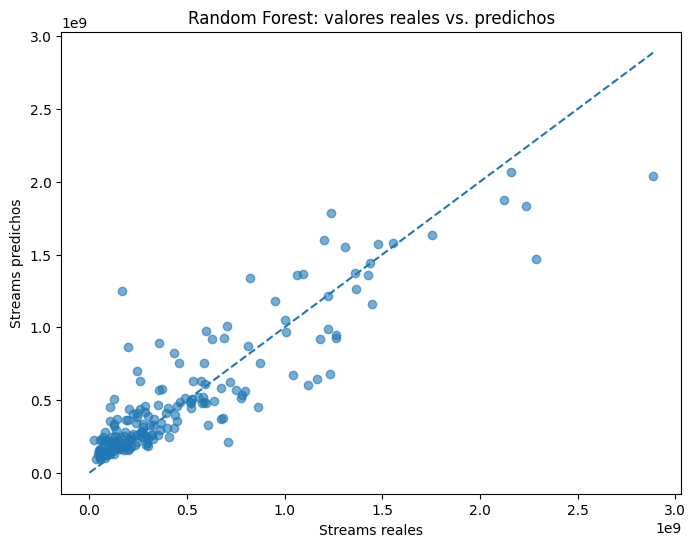

In [22]:
# Gráfico: valores reales vs. valores predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel('Streams reales')
plt.ylabel('Streams predichos')
plt.title('Random Forest: valores reales vs. predichos')

limite_max = max(y_test.max(), y_pred.max())
plt.plot([0, limite_max], [0, limite_max], linestyle='--')

plt.show()


## Comparación con un árbol de decisión individual

La teoría plantea que un solo árbol de decisión tiene bajo sesgo pero alta varianza (se sobreajusta), y que Random Forest reduce esa varianza al promediar muchos árboles. Para comprobarlo, se entrena un único `DecisionTreeRegressor` sobre los mismos datos y se comparan sus métricas contra las del bosque.


Métrica  Árbol individual  Random Forest
    MAE      1.705819e+08   1.478385e+08
   RMSE      2.492617e+08   2.225096e+08
     R²      7.461879e-01   7.977453e-01


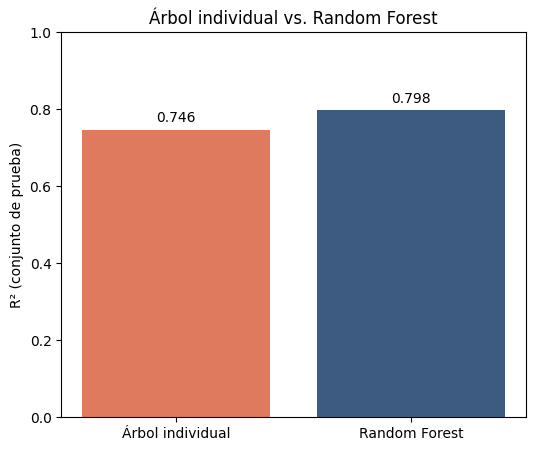

In [23]:
from sklearn.tree import DecisionTreeRegressor

# Árbol de decisión individual, sin límite de profundidad (igual que cada árbol dentro del bosque)
arbol_unico = DecisionTreeRegressor(random_state=42)
arbol_unico.fit(X_train, y_train)

y_pred_arbol = arbol_unico.predict(X_test)

mae_arbol = mean_absolute_error(y_test, y_pred_arbol)
rmse_arbol = np.sqrt(mean_squared_error(y_test, y_pred_arbol))
r2_arbol = r2_score(y_test, y_pred_arbol)

comparacion_modelos = pd.DataFrame({
    'Métrica': ['MAE', 'RMSE', 'R²'],
    'Árbol individual': [mae_arbol, rmse_arbol, r2_arbol],
    'Random Forest': [mae, rmse, r2]
})
print(comparacion_modelos.to_string(index=False))

# Gráfico comparativo de R² entre ambos modelos
plt.figure(figsize=(6, 5))
plt.bar(['Árbol individual', 'Random Forest'], [r2_arbol, r2], color=['#e07a5f', '#3d5a80'])
plt.ylabel('R² (conjunto de prueba)')
plt.title('Árbol individual vs. Random Forest')
plt.ylim(0, 1)
for i, v in enumerate([r2_arbol, r2]):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center')
plt.show()


## Análisis de residuos

Otra técnica de validación mencionada en la teoría es analizar los residuos (diferencia entre el valor real y el predicho). Un buen modelo debería tener residuos distribuidos alrededor de cero, sin un patrón claro frente a los valores predichos (lo contrario indicaría heterocedasticidad o sesgos sistemáticos).


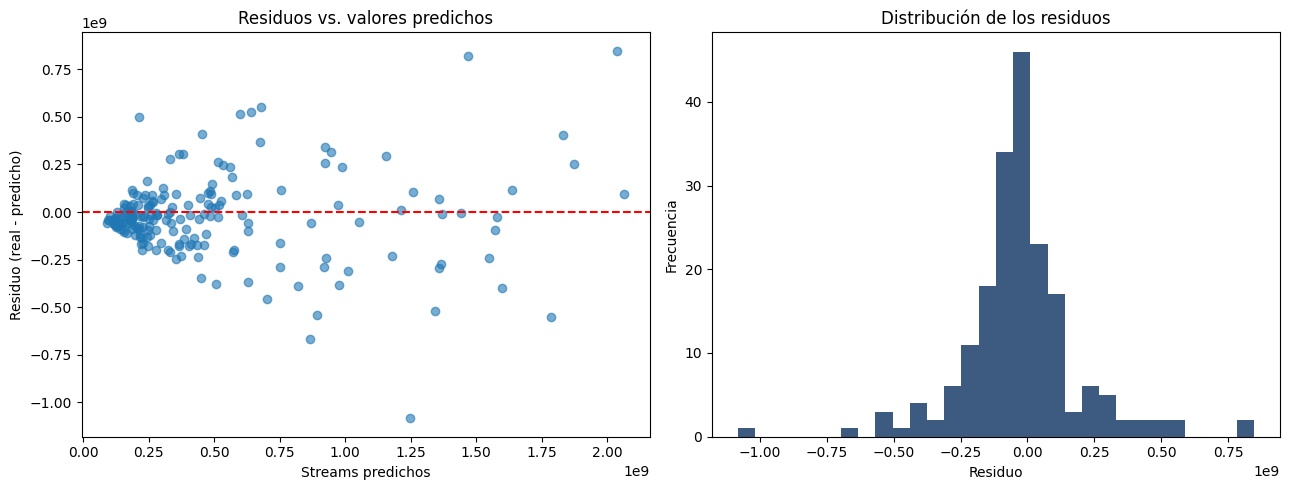

Media de los residuos: -27,496,456
Desviación estándar de los residuos: 220,804,089


In [24]:
residuos = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_pred, residuos, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Streams predichos')
axes[0].set_ylabel('Residuo (real - predicho)')
axes[0].set_title('Residuos vs. valores predichos')

axes[1].hist(residuos, bins=30, color='#3d5a80')
axes[1].set_xlabel('Residuo')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Distribución de los residuos')

plt.tight_layout()
plt.show()

print(f"Media de los residuos: {residuos.mean():,.0f}")
print(f"Desviación estándar de los residuos: {residuos.std():,.0f}")


## Importancia de las variables

Random Forest permite estimar qué variables tuvieron mayor influencia en las predicciones realizadas por el modelo.


In [25]:
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values('Importancia', ascending=False)

importancias.head(15)


,Variable,Importancia
1,in_spotify_playlists,0.235073
5,in_deezer_playlists,0.223117
3,in_apple_playlists,0.144690
30,release_year,0.118308
4,in_apple_charts,0.038620
2,in_spotify_charts,0.031456
32,release_dayofyear,0.030669
6,in_deezer_charts,0.021540
8,bpm,0.017321
10,valence,0.016974


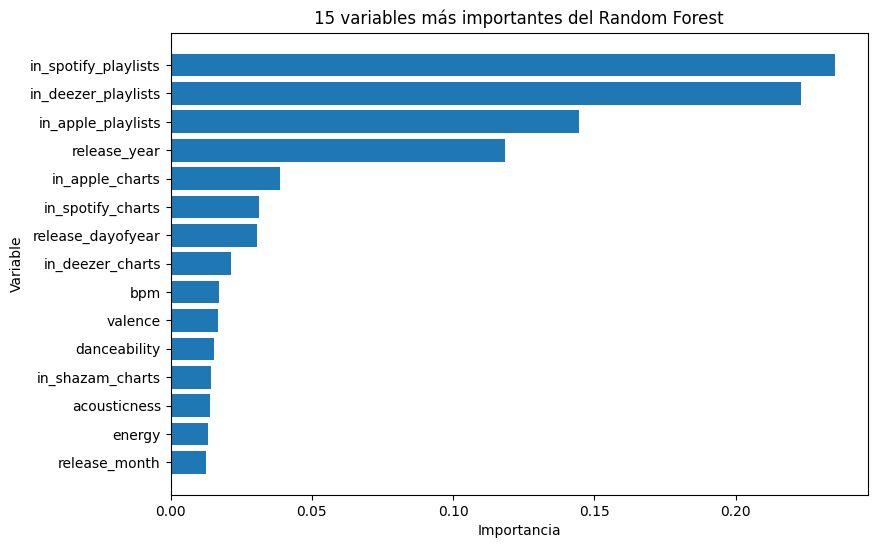

In [26]:
# Mostrar las 15 variables más importantes
top_importancias = importancias.head(15).sort_values('Importancia')

plt.figure(figsize=(9, 6))
plt.barh(top_importancias['Variable'], top_importancias['Importancia'])
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.title('15 variables más importantes del Random Forest')
plt.show()


## Ejemplo de aplicación del modelo

Como ejemplo de aplicación, se toma una observación del conjunto de prueba y se calcula el número de `streams` esperado según el modelo.  
Para predecir una canción nueva, sus datos deben tener las mismas variables y estructura que `X`.


In [27]:
# Ejemplo de aplicación con una canción del conjunto de prueba
ejemplo = X_test.iloc[[0]]

prediccion_ejemplo = modelo_rf.predict(ejemplo)[0]
valor_real = y_test.iloc[0]

print(f"Predicción del modelo: {prediccion_ejemplo:,.0f} streams")
print(f"Valor real:            {valor_real:,.0f} streams")
print(f"Error absoluto:        {abs(valor_real - prediccion_ejemplo):,.0f} streams")


Predicción del modelo: 1,573,492,470 streams
Valor real:            1,479,115,056 streams
Error absoluto:        94,377,414 streams


### Ajuste de hiperparámetros (validación cruzada)

Es recomedable hacer una revision de la validación cruzada para ajustar hiperparámetros. Aquí se prueba un pequeño conjunto de combinaciones de `n_estimators` y `max_depth` con `GridSearchCV` (cv=3) para verificar si los valores usados inicialmente (500 árboles, sin límite de profundidad) son razonables o si existe una combinación que generalice mejor.


In [28]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 10, 20]
}

grid_search = GridSearchCV(
    RandomForestRegressor(max_features='sqrt', random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print(f"R² promedio en validación cruzada: {grid_search.best_score_:.4f}")
print(f"R² del modelo original en el conjunto de prueba: {r2:.4f}")


Mejores hiperparámetros encontrados: {'max_depth': 10, 'n_estimators': 500}
R² promedio en validación cruzada: 0.8077
R² del modelo original en el conjunto de prueba: 0.7977


**Conclusión general**

- Random Forest: un árbol de decisión individual es rápido e interpretable, pero inestable (alta varianza, se sobreajusta a los datos que ve).
- Un ensamble de muchos árboles, entrenados con muestras y variables aleatorias, logra un modelo más robusto sin sacrificar capacidad predictiva.
- La ventaja del bosque sobre un árbol individual no es exclusiva de este dataset: es la razón por la que Random Forest se usa en ventas, diagnóstico médico, detección de fraude o riesgo crediticio, o cualquier problema con relaciones no lineales y ruido en los datos.
- El algoritmo exige más cómputo que un solo árbol y pierde algo de interpretabilidad directa (se compensa con la importancia de variables).
- No extrapola bien fuera del rango de los datos de entrenamiento.
- Su desempeño depende de una buena limpieza y selección de variables previa: el modelo es tan bueno como los datos que se le entregan.
- Random Forest no es una solución universal, sino una herramienta especialmente valiosa cuando la prioridad es la precisión y estabilidad del modelo por encima de la simplicidad de su explicación.

## Bibliografía

IBM. (s. f.). *¿Qué es un Random Forest?* IBM. Recuperado de [https://www.ibm.com/mx-es/think/topics/random-forest]

Inesdi Business Techschool. (s. f.). *Random Forest: Qué es, características y aplicaciones*. Inesdi Digital Business School. Recuperado de [https://www.inesdi.com/blog/random-forest-que-es/]

DataCamp. (s. f.). *Random Forest Regression in Python: A Complete Guide*. DataCamp. Recuperado de [https://www.datacamp.com/es/tutorial/random-forest-regression]

Amat, J. (s. f.). *Random Forest en Python*. Cienciadedatos.net. Recuperado de [https://cienciadedatos.net/documentos/py54-random-forest-valores-nulos-variable-categoricas]

Repositorio Institucional Universidad Nacional de Colombia. (s. f.). *Documento de referencia académico*. Universidad Nacional de Colombia. Recuperado de [https://bffrepositorio.unal.edu.co/server/api/core/bitstreams/5d563eae-8705-499e-b4f6-550117b3a49d/content]

EDC Paris Business School. (s. f.). *How Random Forest works in data science*. EDC Paris. Recuperado de [https://www.edcparis.edu/en/blog/how-random-forest-works-data-science]